# 02 · Training: learning to guess the noise

The whole training idea fits in one sentence:

> **Show the model a noisy image and ask it to guess the noise that was added.**

We always have the right answer, because we added the noise ourselves. The **error** is the gap between the model's guess and the true noise.
Training means nudging the model's internal numbers (its "dials") so that gap shrinks, millions of times over.

We'll train on **handwritten digits** (MNIST, 60,000 small black-and-white images). They're simple enough to learn on a laptop in about 10 minutes.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # lets us import the small `diffusion` helper package
OUT = pathlib.Path("../outputs"); OUT.mkdir(exist_ok=True)

import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "#0a0d1f", "axes.facecolor": "#0a0d1f", "text.color": "#e9ecf8",
                     "axes.labelcolor": "#e9ecf8", "xtick.color": "#8f97ba", "ytick.color": "#8f97ba",
                     "axes.edgecolor": "#2a2f55", "font.size": 11})
torch.manual_seed(0)

training on: mps


0.3%

0.7%

1.0%

1.3%

1.7%

... (348 outputs left out)

99.4%

100.0%

100.0%

60000 training images


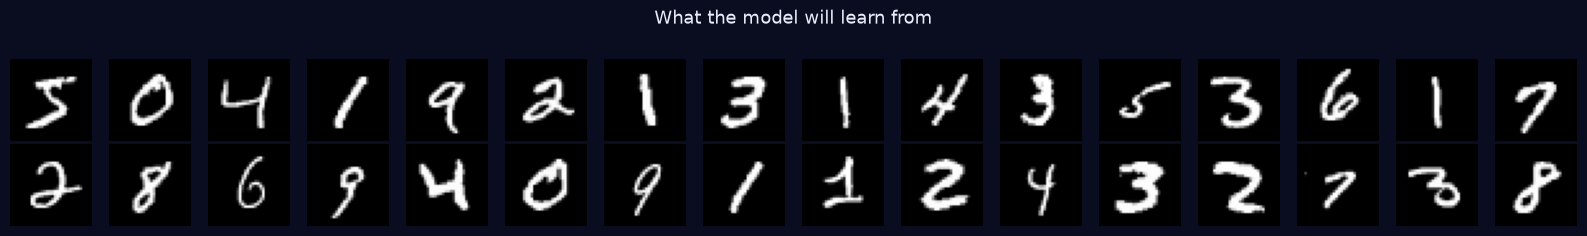

In [2]:
from torchvision import datasets, transforms
from diffusion import NoiseSchedule, TinyUNet

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("training on:", device)

to_tensor = transforms.Compose([transforms.Pad(2), transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])  # 28->32 px, values -1..1
mnist = datasets.MNIST("../data", train=True, download=True, transform=to_tensor)
loader = torch.utils.data.DataLoader(mnist, batch_size=128, shuffle=True, drop_last=True)
print(len(mnist), "training images")

grid = torch.stack([mnist[i][0] for i in range(32)])
fig, axes = plt.subplots(2, 16, figsize=(16, 2.4))
for ax, im in zip(axes.flat, grid):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
plt.suptitle("What the model will learn from", color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "03_mnist_examples.png", dpi=120); plt.show()

## The quiz

Take a real digit, pick a random step `t`, and bury the digit under that much noise (the shortcut from notebook 01).
The model sees **only the noisy image** (plus the step number, and which digit it is). It has to guess the noise.

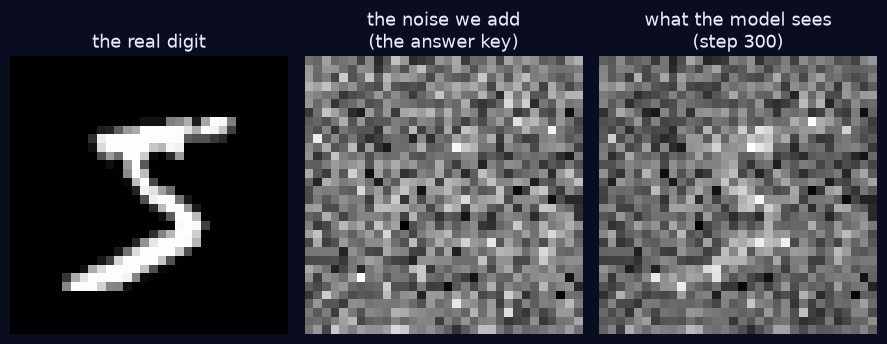

In [3]:
schedule = NoiseSchedule().to(device)
digit, label = mnist[0]
t = torch.tensor([300], device=device)
noisy, true_noise = schedule.add_noise(digit[None].to(device), t)

fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
for ax, im, title in zip(axes, [digit[0], true_noise[0, 0].cpu(), noisy[0, 0].cpu()],
                         ["the real digit", "the noise we add\n(the answer key)", "what the model sees\n(step 300)"]):
    ax.imshow(im, cmap="gray"); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.savefig(OUT / "03_the_quiz.png", dpi=120); plt.show()

## The model and its "dials"

The model is a small **U-Net** (defined in `diffusion/model.py`). It squeezes the image down to see the big picture, then expands it back to place details.
Every number inside it is a dial that training will adjust. Big image models have billions; ours has well under a million.

In [4]:
model = TinyUNet().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} dials (parameters)")

505,025 dials (parameters)


## The training loop

For every batch of 128 digits:

1. pick a random step `t` for each image and add that much noise,
2. ask the model to guess the noise,
3. measure the **error** (mean squared gap between guess and truth),
4. **backpropagation** works out which way to turn each dial to shrink the error, and **gradient descent** turns them a tiny bit.

One small extra: 10% of the time we hide which digit it is. That teaches the model to work without a label too, which we use in notebook 03 to *steer* it.

We also keep a slowly-updated average copy of the dials (an "EMA"). It makes the final images a bit cleaner.

In [5]:
import copy, time

ema = copy.deepcopy(model).eval()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
epochs = 10
sched_lr = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=epochs * len(loader), pct_start=0.1)
losses = []

for epoch in range(epochs):
    start = time.time()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        labels = torch.where(torch.rand(len(labels), device=device) < 0.1, TinyUNet.NO_LABEL, labels)  # hide the label 10% of the time

        t = torch.randint(0, schedule.steps, (len(images),), device=device)   # 1. random step per image
        noisy, noise = schedule.add_noise(images, t)                          #    ...and bury it in noise
        guess = model(noisy, t, labels)                                       # 2. the model's guess
        loss = torch.nn.functional.mse_loss(guess, noise)                     # 3. the error

        opt.zero_grad()
        loss.backward()                                                       # 4. which way to turn each dial
        opt.step(); sched_lr.step()                                           #    ...turn them a little

        with torch.no_grad():                                                 # slowly-updated average of the dials
            for p_ema, p in zip(ema.parameters(), model.parameters()):
                p_ema.lerp_(p, 0.001)
        losses.append(loss.item())
    print(f"epoch {epoch + 1}/{epochs}  error {np.mean(losses[-len(loader):]):.4f}  ({time.time() - start:.0f}s)")

pathlib.Path("../checkpoints").mkdir(exist_ok=True)
torch.save(ema.state_dict(), "../checkpoints/tiny_unet_mnist.pt")
print("saved checkpoints/tiny_unet_mnist.pt")

epoch 1/10  error 0.1613  (75s)


epoch 2/10  error 0.0270  (76s)


epoch 3/10  error 0.0230  (70s)


epoch 4/10  error 0.0211  (69s)


epoch 5/10  error 0.0204  (70s)


epoch 6/10  error 0.0192  (64s)


epoch 7/10  error 0.0189  (39s)


epoch 8/10  error 0.0183  (38s)


epoch 9/10  error 0.0182  (38s)


epoch 10/10  error 0.0178  (44s)
saved checkpoints/tiny_unet_mnist.pt


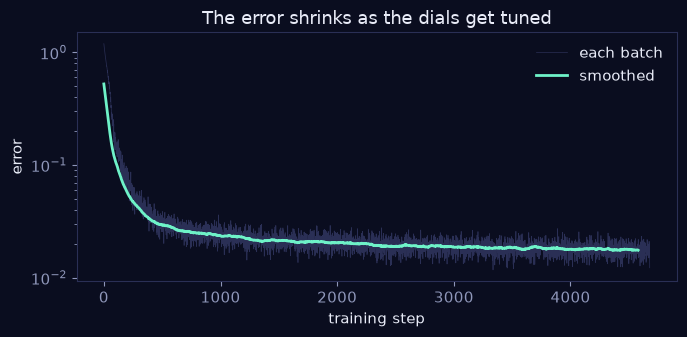

In [6]:
smooth = np.convolve(losses, np.ones(100) / 100, mode="valid")
plt.figure(figsize=(7, 3.5))
plt.plot(losses, color="#2a2f55", lw=0.5, label="each batch")
plt.plot(smooth, color="#6ef2c8", lw=2, label="smoothed")
plt.yscale("log"); plt.xlabel("training step"); plt.ylabel("error"); plt.legend(frameon=False)
plt.title("The error shrinks as the dials get tuned")
plt.tight_layout(); plt.savefig(OUT / "03_loss_curve.png", dpi=120); plt.show()

## Did it learn?

Give the trained model a digit it has never seen (from the separate test set), bury it in noise, and compare its guess to the real noise.
If the guess is good, **noisy image minus the guessed noise** should bring the digit back.

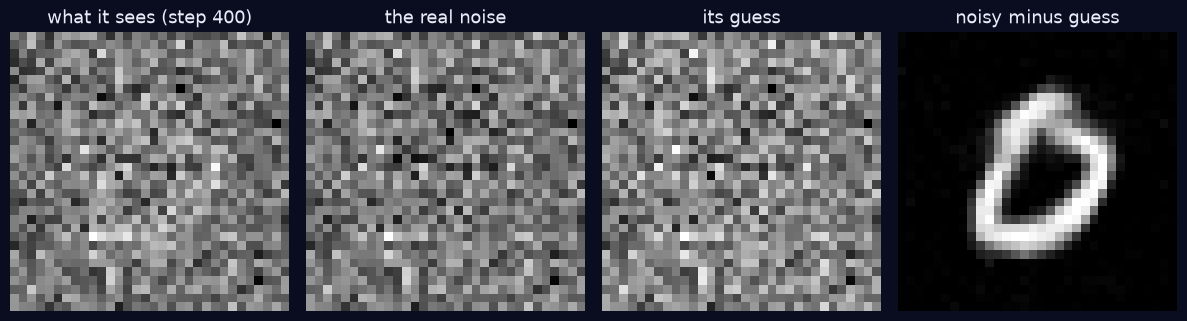

In [7]:
test = datasets.MNIST("../data", train=False, download=True, transform=to_tensor)
digit, label = test[3]
t = torch.tensor([400], device=device)
torch.manual_seed(1)
noisy, true_noise = schedule.add_noise(digit[None].to(device), t)
with torch.no_grad():
    guess = ema(noisy, t, torch.tensor([label], device=device))
a = schedule.alpha_bars[t].view(-1, 1, 1, 1)
recovered = (noisy - (1 - a).sqrt() * guess) / a.sqrt()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, im, title in zip(axes, [noisy, true_noise, guess, recovered.clamp(-1, 1)],
                         ["what it sees (step 400)", "the real noise", "its guess", "noisy minus guess"]):
    ax.imshow(im[0, 0].cpu(), cmap="gray"); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.savefig(OUT / "03_noise_guess.png", dpi=120); plt.show()

**Takeaway:** nobody told the model what a "3" looks like. By guessing noise millions of times, it absorbed the loose patterns of handwritten digits (strokes, loops, where ink tends to go).
That knowledge is what lets it create brand new digits from static in notebook **03**.